# 02 — Feature Validation

Checks the engineered features from `src/features/build_features.py` before modeling.

**Uses the training split only.** Validation and test data stay untouched until Phase 4, so nothing here can bias the final evaluation.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src import config
from src.data.split import load_splits
from src.features.build_features import ENGINEERED_BINARY, ENGINEERED_NUMERIC, add_features
from src.features.pipeline import (RAW_CATEGORICAL, RAW_NUMERIC, build_preprocessor,
                                   make_model_pipeline, split_xy)
from src.utils.seed import set_seed

set_seed()
warnings.filterwarnings('ignore', category=UserWarning)
sns.set_theme(style='whitegrid', palette='deep')
FIG = config.FIGURES_DIR

def save(fig, name):
    fig.savefig(FIG / f'features_{name}.png', dpi=120, bbox_inches='tight')

train = load_splits().train
f = add_features(train)
overall = train[config.TARGET_COL].mean()
print(f'train rows: {len(train):,} | churn rate: {overall:.3f}')

train rows: 4,929 | churn rate: 0.265


## 1. Binary flags: churn rate when the flag is on vs. off

,feature,share_on,churn_if_on,churn_if_off,lift_on
6,fiber_no_protection,0.117,0.648,0.215,2.440
0,is_new_customer,0.213,0.514,0.198,1.938
4,electronic_check,0.337,0.457,0.168,1.721
7,m2m_no_techsupport,0.454,0.454,0.109,1.710
2,is_fiber,0.437,0.422,0.144,1.590
1,has_internet,0.782,0.320,0.071,1.204
5,has_family,0.533,0.196,0.345,0.737
3,auto_pay,0.434,0.155,0.350,0.583


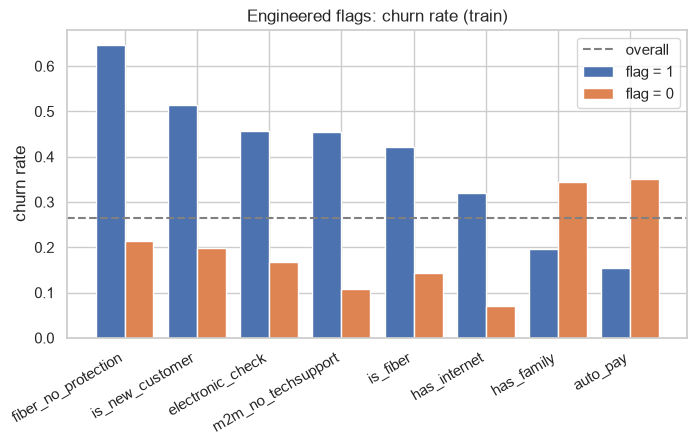

In [2]:
rows = []
for c in ENGINEERED_BINARY:
    g = f.groupby(c)[config.TARGET_COL].mean()
    rows.append({'feature': c, 'share_on': f[c].mean(), 'churn_if_on': g.get(1, np.nan),
                 'churn_if_off': g.get(0, np.nan)})
flags = pd.DataFrame(rows)
flags['lift_on'] = flags['churn_if_on'] / overall
flags = flags.sort_values('churn_if_on', ascending=False)
display(flags.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(flags))
ax.bar(x - 0.2, flags['churn_if_on'], 0.4, label='flag = 1')
ax.bar(x + 0.2, flags['churn_if_off'], 0.4, label='flag = 0')
ax.axhline(overall, ls='--', c='grey', label='overall')
ax.set_xticks(x, flags['feature'], rotation=30, ha='right')
ax.set(ylabel='churn rate', title='Engineered flags: churn rate (train)')
ax.legend()
save(fig, 'binary_flags')

**Findings:** `fiber_no_protection` is the strongest new flag — 11.7% of customers, churning at about 65% (2.4× the average). `is_new_customer` (≤ 6 months) churns at about 51%. `auto_pay` and `has_family` are protective (about 15–20%).

## 2. Service counts: is there a dose-response?

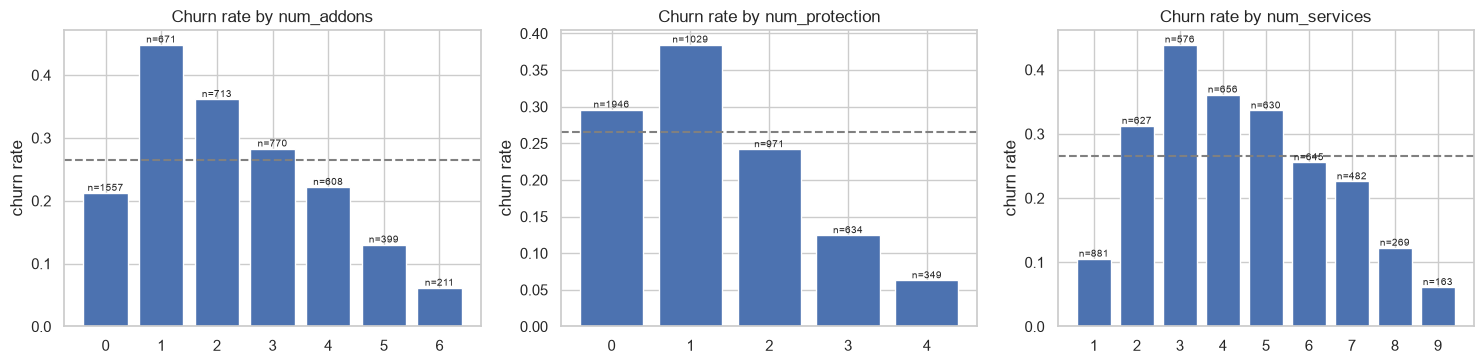

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axes, ['num_addons', 'num_protection', 'num_services']):
    g = f.groupby(c)[config.TARGET_COL].agg(['mean', 'size'])
    ax.bar(g.index.astype(str), g['mean'])
    ax.axhline(overall, ls='--', c='grey')
    for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
        ax.annotate(f'n={n}', (i, m), ha='center', va='bottom', fontsize=7)
    ax.set(title=f'Churn rate by {c}', ylabel='churn rate')
fig.tight_layout()
save(fig, 'service_counts')

**Findings:** `num_protection` shows a clear dose-response: each extra protection service lowers churn, from about 38% with 1 to about 6% with all 4. `num_addons` is not monotonic. Zero add-ons is low (~21%) because it is mostly customers without internet, who are low-risk anyway. Tree models handle this naturally; for logistic regression the `has_internet` flag lets the model separate the two groups.

## 3. Engineered numeric features

,churn_rate,customers,median_tenure
charge_trend_ratio,,,
"(0.668, 0.974]",0.260,986,18.0
"(0.974, 0.995]",0.195,986,47.0
"(0.995, 1.004]",0.409,985,9.0
"(1.004, 1.028]",0.203,986,47.0
"(1.028, 1.451]",0.261,986,18.0


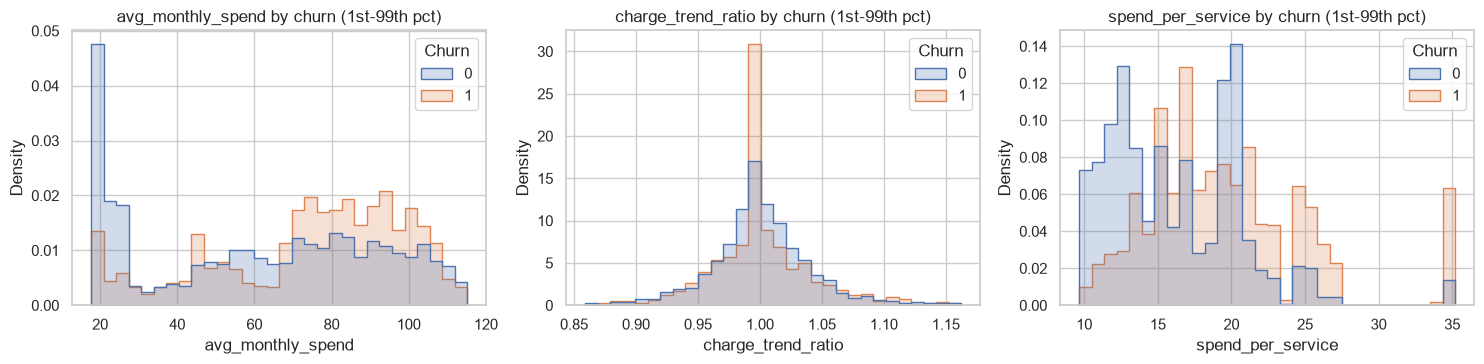

In [4]:
num_eng = ['avg_monthly_spend', 'charge_trend_ratio', 'spend_per_service']
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axes, num_eng):
    lo, hi = f[c].quantile([0.01, 0.99])
    sns.histplot(data=f[f[c].between(lo, hi)], x=c, hue=config.TARGET_COL, bins=30,
                 stat='density', common_norm=False, element='step', ax=ax)
    ax.set_title(f'{c} by churn (1st-99th pct)')
fig.tight_layout()
save(fig, 'numeric_engineered')

trend = f.groupby(pd.qcut(f['charge_trend_ratio'], 5, duplicates='drop'), observed=True)
display(trend[config.TARGET_COL].agg(churn_rate='mean', customers='size',
      median_tenure=lambda s: f.loc[s.index, 'tenure'].median()).round(3))

**Findings:** `charge_trend_ratio` (current bill vs. lifetime average) is centered tightly on 1.0. Its signal is **weak and not monotonic**: the middle bin's high churn comes from 1-month customers, whose ratio is exactly 1 by definition, so it partly duplicates tenure. It is kept for now and Phase 5 SHAP will show whether it adds anything. `spend_per_service` separates better: churners pay more per service they use.

## 4. Mutual information with churn (preprocessed features, train)

Engineered features in top 10: ['num__contract_months', 'num__spend_per_service', 'bin__m2m_no_techsupport', 'num__num_addons']


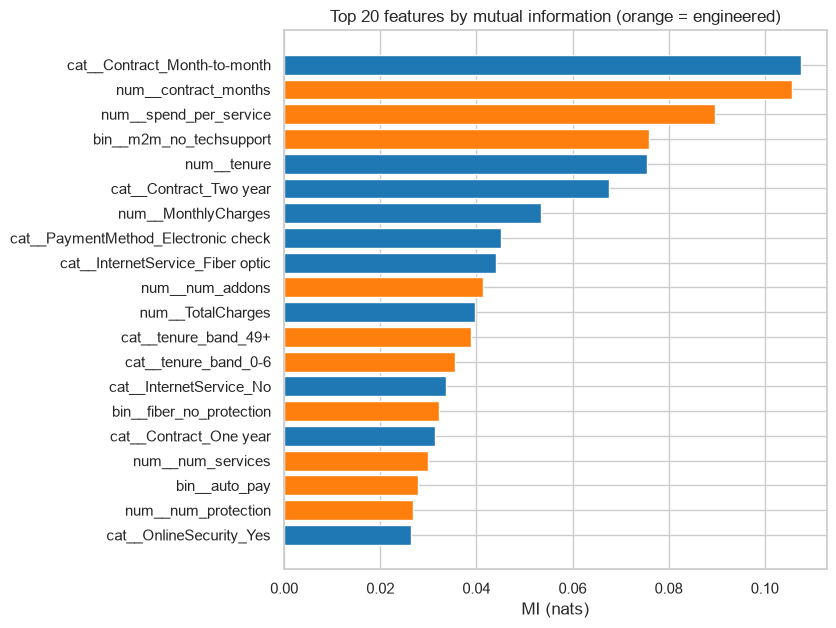

In [5]:
X, y = split_xy(train)
pre = build_preprocessor().fit(X)
Xt = pre.transform(X)
mi = pd.Series(mutual_info_classif(Xt, y, random_state=config.SEED), index=Xt.columns)
mi = mi.sort_values(ascending=False)
engineered = {f'num__{c}' for c in ENGINEERED_NUMERIC} | {f'bin__{c}' for c in ENGINEERED_BINARY}
engineered |= {c for c in Xt.columns if c.startswith('cat__tenure_band')}

top = mi.head(20)[::-1]
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(top.index, top.values, color=['tab:orange' if c in engineered else 'tab:blue' for c in top.index])
ax.set(title='Top 20 features by mutual information (orange = engineered)', xlabel='MI (nats)')
save(fig, 'mutual_information')
print('Engineered features in top 10:', [c for c in mi.head(10).index if c in engineered])

## 5. Redundancy check

In [6]:
# all engineered + one-hot raw columns, before DUPLICATE_FEATURES are excluded
full = pd.get_dummies(add_features(X), drop_first=True, dtype=float)
corr = full.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
display(pairs[pairs > 0.9].round(3).to_frame('|r|'))

|r|
is_fiber         InternetService_Fiber optic     1.000
has_internet     InternetService_No              1.000
electronic_check PaymentMethod_Electronic check  1.000
MonthlyCharges   avg_monthly_spend               0.996
num_addons       num_services                    0.953
                 num_protection                  0.915

**Findings (this check caught two real issues):**

1. **A labelling bug, now fixed.** The first run of this table showed impossible pairs such as `InternetService_No` = `electronic_check`. The feature step returned columns in a different order than the names it reported, and sklearn's `set_output` renames by position. Fixed in `build_features.py` (one shared `ENGINEERED_ALL` order) and covered by `test_preprocessor_columns_are_correctly_labelled`.
2. **Exact duplicates.** With correct labels, 4 engineered flags are exact copies of one-hot columns and `avg_monthly_spend` has r = 0.996 with `MonthlyCharges`. These are listed in `DUPLICATE_FEATURES` (`src/features/pipeline.py`) and **excluded from model inputs**, because duplicates split SHAP credit between copies. The pairs below are computed on all engineered columns, before that exclusion.

The remaining high correlations (`num_addons` vs `num_services` / `num_protection`, `contract_months` vs `Contract`) are related but not identical, so they stay.

## 6. Do engineered features help? (5-fold CV on train only)

Same logistic regression, raw columns vs. raw + engineered. The scoring metric is PR-AUC (average precision). Preprocessing is refit inside every fold, so this is a fair, leakage-free comparison. This is a sanity check only; model selection happens in Phase 4.

In [7]:
cv = StratifiedKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.SEED)
lr = LogisticRegression(max_iter=2000, class_weight='balanced')

raw_pipe = Pipeline([
    ('prep', ColumnTransformer([
        ('num', StandardScaler(), RAW_NUMERIC + ['SeniorCitizen']),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), RAW_CATEGORICAL)])),
    ('model', lr)])
eng_pipe = make_model_pipeline(lr)

results = {}
for name, pipe in [('raw only', raw_pipe), ('raw + engineered', eng_pipe)]:
    s = cross_val_score(pipe, X, y, cv=cv, scoring=config.PRIMARY_METRIC)
    results[name] = s
    print(f'{name:<18} PR-AUC {s.mean():.4f} ± {s.std():.4f}')
diff = results['raw + engineered'] - results['raw only']
print(f'per-fold gain: {np.round(diff, 4)} | folds improved: {(diff > 0).sum()}/{len(diff)}')

raw only           PR-AUC 0.6640 ± 0.0225


raw + engineered   PR-AUC 0.6629 ± 0.0262
per-fold gain: [ 0.0072 -0.0036 -0.011  -0.0003  0.0022] | folds improved: 2/5


**Finding: no gain for logistic regression.** Raw-only and raw + engineered score within about 0.001 PR-AUC, well inside fold-to-fold noise (±0.02), and improve only 2 of 5 folds. The engineered features re-express signal the linear model already gets from the raw columns.

**Decision:** keep the engineered features (they make SHAP explanations far more readable for the business report), but **don't claim a gain**. In Phase 4 every model is cross-validated on both feature sets, and the engineered set is kept for tree models only if it actually helps there.